# Pulso Fase 4 - Notebook 2: CNN do zero e Transfer Learning (ResNet50)
Autor: Richard Schmitz | RM 567951 | Turma 2TIAOR-2026
Projeto: Pulso, Inteligência Cardiológica com Consciência de Dados (CardioIA, FIAP)
## Objetivo
Treinar e comparar duas abordagens para classificar radiografias de tórax em **cardiomegalia (1)** contra **sem achados (0)**, usando as partições geradas no Notebook 1: uma CNN simples treinada do zero e Transfer Learning com ResNet50 pré-treinada na ImageNet. Este notebook cobre a Parte 2 do enunciado (CNN, Transfer Learning e métricas). O protótipo de apresentação fica no Notebook 3 e a análise de fairness no Notebook 4.
## Decisões e justificativas
| Decisão | Escolha | Por quê |
|---|---|---|
| Desbalanceamento (cerca de 4,4% de positivos) | Peso de classe na função de perda, calculado no treino | Sem isso o modelo aprende a responder sempre "sem achados" |
| Métrica de acompanhamento no treino | Área sob a curva Precisão x Recall (AUC-PR) na validação | A acurácia engana quando 95,6% das imagens são negativas |
| Limiar de decisão | Escolhido na **validação**, maximizando o F1. Aplicado uma única vez no teste | Escolher o limiar no teste vazaria informação do teste |
| Conjunto de teste | Usado somente na avaliação final de cada modelo | Evita estimar o desempenho com dados que influenciaram o treino |
| Incerteza | Intervalo de confiança de 95% por bootstrap **por paciente** (1000 repetições) | O teste tem poucos positivos. Reamostrar por paciente respeita a divisão do Notebook 1 |
| Aumento de dados | Rotação pequena, deslocamento, zoom e contraste. **Sem espelhamento** | Espelhar troca o lado do coração |
| Pré-processamento do modelo | Dentro do modelo: CNN divide por 255. ResNet50 replica o canal para 3 e subtrai a média da ImageNet | Os arquivos continuam em uint8, como definido no Notebook 1 |
| Ajuste fino (ResNet50) | Fase 1: só a cabeça. Fase 2: último bloco convolucional (`conv5_`), sem camadas BatchNormalization | Com poucos positivos, liberar pouco reduz o risco de sobreajuste |
| Semente | 42 | Reprodutibilidade (a GPU pode introduzir pequenas variações) |
## Aviso
Projeto acadêmico. Nada aqui produz diagnóstico nem deve apoiar decisão clínica.

In [17]:
import os
import sys
import json
import shutil
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_auc_score, average_precision_score,
                             roc_curve, precision_recall_curve, classification_report)
try:
    from IPython.display import display
except ImportError:
    display = print
warnings.filterwarnings("ignore")

SEED = 42        # mesma semente do Notebook 1
TAMANHO = 224    # lado da imagem, igual ao Notebook 1
BATCH = 32
keras.utils.set_random_seed(SEED)

try:
    import google.colab  # noqa: F401
    COLAB = True
except ImportError:
    COLAB = False
print("Ambiente:", "Google Colab" if COLAB else "Local")
gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow:", tf.__version__, "| GPU:", [g.name for g in gpus] if gpus else "nenhuma")
if not gpus:
    print("ATENCAO: sem GPU o treino fica muito lento. No Colab: Ambiente de execucao, Alterar tipo, GPU.")

Ambiente: Google Colab
TensorFlow: 2.21.0 | GPU: ['/physical_device:GPU:0']


## 1. Pastas de trabalho
Mesma lógica do Notebook 1: no Colab, usa o Google Drive (`MyDrive/Pulso_F4/saida`), onde estão os arrays `.npz`. Os modelos treinados também são salvos ali.

In [18]:
BASE = Path("/content/pulso_f4") if COLAB else Path("./pulso_f4")
if COLAB:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        BASE = Path("/content/drive/MyDrive/Pulso_F4")
    except Exception as erro:
        print("Drive nao montado, usando o disco temporario:", erro)
SAIDA = BASE / "saida"
necessarios = ["treino.npz", "validacao.npz", "teste.npz", "splits.csv"]
faltando = [n for n in necessarios if not (SAIDA / n).exists()]
if faltando:
    raise FileNotFoundError("Arquivos do Notebook 1 nao encontrados em %s: %s. Execute o Notebook 1 antes." % (SAIDA, faltando))
print("Saida:", SAIDA)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saida: /content/drive/MyDrive/Pulso_F4/saida


## 2. Carregamento e conferência dos dados
Os arrays estão em `uint8`, com forma `(N, 224, 224)`. Ganham um eixo de canal. O notebook confere formato, contagens e a ausência de pacientes repetidos entre as partições. Se existir o `pipeline_resumo.json` do Notebook 1, as contagens são comparadas com ele.

In [19]:
def carregar(nome):
    dados = np.load(SAIDA / ("%s.npz" % nome), allow_pickle=False)
    X, y, img = dados["X"], dados["y"], dados["imagem"]
    assert X.dtype == np.uint8 and X.ndim == 3 and X.shape[1:] == (TAMANHO, TAMANHO), "Formato inesperado em %s: %s %s" % (nome, X.dtype, X.shape)
    assert len(X) == len(y) == len(img)
    return X[..., None], y.astype(np.float32), img

Xtr, ytr, img_tr = carregar("treino")
Xva, yva, img_va = carregar("validacao")
Xte, yte, img_te = carregar("teste")

splits = pd.read_csv(SAIDA / "splits.csv").set_index("imagem")
for nome, img in [("treino", img_tr), ("validacao", img_va), ("teste", img_te)]:
    assert set(img) <= set(splits.index), "Imagens fora do splits.csv em " + nome
    assert (splits.loc[img, "particao"] == nome).all(), "Particao inconsistente em " + nome
pac = {n: set(splits.loc[i, "paciente"]) for n, i in [("treino", img_tr), ("validacao", img_va), ("teste", img_te)]}
assert not (pac["treino"] & pac["validacao"]) and not (pac["treino"] & pac["teste"]) and not (pac["validacao"] & pac["teste"]), "Paciente repetido entre particoes"
pac_teste = splits.loc[img_te, "paciente"].values

contagens = {"treino": (len(ytr), int(ytr.sum())), "validacao": (len(yva), int(yva.sum())), "teste": (len(yte), int(yte.sum()))}
resumo_nb1 = SAIDA / "pipeline_resumo.json"
if resumo_nb1.exists():
    r = json.loads(resumo_nb1.read_text(encoding="utf-8"))["particoes"]
    for nome, (n, pos) in contagens.items():
        assert r[nome]["imagens"] == n and r[nome]["positivos"] == pos, "Contagem diferente do pipeline_resumo.json em " + nome
    print("Contagens conferidas com o pipeline_resumo.json do Notebook 1.")
else:
    print("pipeline_resumo.json nao encontrado: contagens nao comparadas.")
tabela = pd.DataFrame(contagens, index=["imagens", "positivos"]).T
tabela["prevalencia_%"] = (100 * tabela["positivos"] / tabela["imagens"]).round(2)
display(tabela)
print("Nenhum paciente aparece em mais de uma particao (verificado).")

Contagens conferidas com o pipeline_resumo.json do Notebook 1.


,imagens,positivos,prevalencia_%
treino,2277,100,4.39
validacao,462,22,4.76
teste,446,19,4.26


Nenhum paciente aparece em mais de uma particao (verificado).


## 3. Funções de avaliação
Todas as métricas do enunciado (acurácia, matriz de confusão, precisão, recall e F1) mais AUC-ROC e AUC-PR, que não dependem do limiar. O limiar é escolhido na validação e o intervalo de confiança vem de bootstrap por paciente.

In [20]:
def escolher_limiar(y, p):
    """Escolhe, na validacao, o limiar que maximiza o F1. Devolve (limiar, f1 na validacao)."""
    candidatos = np.round(np.arange(0.02, 0.99, 0.01), 2)
    f1s = [f1_score(y, (p >= t).astype(int), zero_division=0) for t in candidatos]
    i = int(np.argmax(f1s))
    return float(candidatos[i]), float(f1s[i])

def calcular_metricas(y, p, limiar):
    """Metricas de classificacao no limiar dado, mais AUC-ROC e AUC-PR (independentes do limiar)."""
    y = np.asarray(y).astype(int)
    pred = (np.asarray(p) >= limiar).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {
        "acuracia": float(accuracy_score(y, pred)),
        "precisao": float(precision_score(y, pred, zero_division=0)),
        "recall": float(recall_score(y, pred, zero_division=0)),
        "f1": float(f1_score(y, pred, zero_division=0)),
        "especificidade": float(tn / (tn + fp)) if (tn + fp) else float("nan"),
        "auc_roc": float(roc_auc_score(y, p)),
        "auc_pr": float(average_precision_score(y, p)),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }

def intervalo_bootstrap(y, p, pacientes, limiar, n_rep=1000, seed=SEED):
    """IC de 95% por bootstrap reamostrando pacientes (nao imagens). Ignora reamostras sem as duas classes."""
    y = np.asarray(y).astype(int)
    p = np.asarray(p)
    grupos = [g.index.values for _, g in pd.DataFrame({"pac": np.asarray(pacientes)}).groupby("pac")]
    rng = np.random.default_rng(seed)
    nomes = ["precisao", "recall", "f1", "auc_roc", "auc_pr"]
    amostras = {n: [] for n in nomes}
    for _ in range(n_rep):
        idx = np.concatenate([grupos[i] for i in rng.integers(0, len(grupos), len(grupos))])
        if y[idx].sum() == 0 or y[idx].sum() == len(idx):
            continue
        m = calcular_metricas(y[idx], p[idx], limiar)
        for n in nomes:
            amostras[n].append(m[n])
    ic = {n: (float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))) for n, v in amostras.items()}
    ic["repeticoes_validas"] = len(amostras["recall"])
    return ic

def grafico_matriz(m, titulo, caminho):
    cm = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
    fig, ax = plt.subplots(figsize=(4.2, 3.8))
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, str(v), ha="center", va="center", fontsize=14, color="white" if v > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["sem achados", "cardiomegalia"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["sem achados", "cardiomegalia"])
    ax.set_xlabel("previsto"); ax.set_ylabel("real"); ax.set_title(titulo, fontsize=10)
    plt.tight_layout(); plt.savefig(caminho, dpi=130); plt.show()

def grafico_treino(historico, titulo, caminho):
    fig, eixos = plt.subplots(1, 2, figsize=(10, 3.4))
    for ax, chave, nome in [(eixos[0], "loss", "perda"), (eixos[1], "auc_pr", "AUC-PR")]:
        ax.plot(historico[chave], label="treino")
        ax.plot(historico["val_" + chave], label="validacao")
        ax.set_title("%s - %s" % (titulo, nome), fontsize=10); ax.set_xlabel("epoca"); ax.legend()
    plt.tight_layout(); plt.savefig(caminho, dpi=130); plt.show()

## 4. Dados para o treino e peso de classe
O peso de cada classe é `N / (2 x N_classe)`, calculado só com o treino. O conjunto de treino é embaralhado a cada época. Validação e teste mantêm a ordem, para as previsões baterem com os rótulos.

In [21]:
def montar_ds(X, y, treino=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if treino:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH).map(lambda a, b: (tf.cast(a, tf.float32), b), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

ds_treino = montar_ds(Xtr, ytr, treino=True)
ds_val = montar_ds(Xva, yva)
ds_teste = montar_ds(Xte, yte)

n = len(ytr); n_pos = int(ytr.sum()); n_neg = n - n_pos
PESOS = {0: n / (2 * n_neg), 1: n / (2 * n_pos)}
print("Peso de classe:", {k: round(v, 3) for k, v in PESOS.items()})

def n_params(pesos):
    return int(sum(np.prod(w.shape) for w in pesos))

def camada_aumento():
    """Aumento de dados leve, ativo so no treino. Sem espelhamento horizontal."""
    return keras.Sequential([
        layers.RandomRotation(0.03, fill_mode="constant"),
        layers.RandomTranslation(0.05, 0.05, fill_mode="constant"),
        layers.RandomZoom(0.1, fill_mode="constant"),
        layers.RandomContrast(0.1),
    ], name="aumento_de_dados")

EPOCAS_CNN = 40
PACIENCIA_CNN = 8
EPOCAS_FASE1 = 15
EPOCAS_FASE2 = 15
PACIENCIA_RESNET = 5

def treinar(modelo, epocas, lr, paciencia):
    """Compila e treina. Monitora a AUC-PR na validacao e restaura os melhores pesos."""
    modelo.compile(
        optimizer=keras.optimizers.Adam(lr),
        loss="binary_crossentropy",
        metrics=[keras.metrics.AUC(name="auc"), keras.metrics.AUC(name="auc_pr", curve="PR")],
    )
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_auc_pr", mode="max", patience=paciencia, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_auc_pr", mode="max", factor=0.5, patience=max(2, paciencia // 2), min_lr=1e-7),
    ]
    h = modelo.fit(ds_treino, validation_data=ds_val, epochs=epocas, class_weight=PESOS, callbacks=callbacks, verbose=2)
    return h.history

Peso de classe: {0: 0.523, 1: 11.385}


## 5. Avaliação de um modelo
Passo único e igual para os dois modelos: previsões na validação, escolha do limiar, previsões no teste, métricas e intervalo de confiança. As previsões são salvas em CSV para o Notebook 4 (fairness) reaproveitar sem retreinar.

In [22]:
RESULTADOS = {}
PREVISOES = {}

def avaliar_modelo(chave, rotulo, modelo):
    p_val = modelo.predict(ds_val, verbose=0).ravel()
    limiar, f1_val = escolher_limiar(yva, p_val)
    p_teste = modelo.predict(ds_teste, verbose=0).ravel()
    m = calcular_metricas(yte, p_teste, limiar)
    ic = intervalo_bootstrap(yte, p_teste, pac_teste, limiar)
    RESULTADOS[chave] = {"rotulo": rotulo, "limiar": limiar, "f1_validacao_no_limiar": f1_val, "teste": m, "ic95": ic}
    PREVISOES[chave] = p_teste
    pd.DataFrame({"imagem": img_va, "y": yva.astype(int), "prob": p_val}).to_csv(SAIDA / ("pred_val_%s.csv" % chave), index=False)
    pd.DataFrame({"imagem": img_te, "y": yte.astype(int), "prob": p_teste}).to_csv(SAIDA / ("pred_teste_%s.csv" % chave), index=False)
    print("== %s ==" % rotulo)
    print("Limiar escolhido na validacao: %.2f (F1 na validacao: %.3f)" % (limiar, f1_val))
    print("Teste: %d imagens, %d positivos" % (len(yte), int(yte.sum())))
    print(classification_report(yte.astype(int), (p_teste >= limiar).astype(int), target_names=["sem achados", "cardiomegalia"], digits=3, zero_division=0))
    for nome in ["acuracia", "precisao", "recall", "f1", "especificidade", "auc_roc", "auc_pr"]:
        faixa = " IC95%% [%.3f - %.3f]" % ic[nome] if nome in ic else ""
        print("%-15s %.3f%s" % (nome, m[nome], faixa))
    print("Repeticoes de bootstrap validas: %d" % ic["repeticoes_validas"])
    grafico_matriz(m, "%s (teste, limiar %.2f)" % (rotulo, limiar), SAIDA / ("nb2_matriz_confusao_%s.png" % chave))

# Referencia: um classificador que responde sempre "sem achados"
baseline = calcular_metricas(yte, np.zeros(len(yte)), 0.5)
print("Referencia (sempre 'sem achados') no teste: acuracia %.3f | recall %.3f" % (baseline["acuracia"], baseline["recall"]))

Referencia (sempre 'sem achados') no teste: acuracia 0.957 | recall 0.000


## 6. Abordagem 1: CNN simples treinada do zero
Cinco blocos convolucionais (Conv, BatchNormalization, ReLU, MaxPooling) com 16, 32, 64, 128 e 128 filtros, seguidos de média global, Dropout de 0,4 e uma saída sigmoide. A rede é pequena de propósito: com 100 positivos no treino, uma rede grande sobreajusta.

Parametros da CNN simples: 245969
Epoch 1/40
72/72 - 6s - 82ms/step - auc: 0.5216 - auc_pr: 0.0469 - loss: 0.7954 - val_auc: 0.4955 - val_auc_pr: 0.0439 - val_loss: 0.9584 - learning_rate: 0.0010
Epoch 2/40
72/72 - 2s - 25ms/step - auc: 0.5313 - auc_pr: 0.0454 - loss: 0.7240 - val_auc: 0.3697 - val_auc_pr: 0.0357 - val_loss: 1.0173 - learning_rate: 0.0010
Epoch 3/40
72/72 - 2s - 25ms/step - auc: 0.5737 - auc_pr: 0.0594 - loss: 0.7060 - val_auc: 0.3628 - val_auc_pr: 0.0350 - val_loss: 0.9625 - learning_rate: 0.0010
Epoch 4/40
72/72 - 2s - 25ms/step - auc: 0.6002 - auc_pr: 0.0626 - loss: 0.6944 - val_auc: 0.4821 - val_auc_pr: 0.0513 - val_loss: 0.9833 - learning_rate: 0.0010
Epoch 5/40
72/72 - 2s - 25ms/step - auc: 0.5670 - auc_pr: 0.0561 - loss: 0.7192 - val_auc: 0.4580 - val_auc_pr: 0.0490 - val_loss: 0.7749 - learning_rate: 0.0010
Epoch 6/40
72/72 - 2s - 25ms/step - auc: 0.6182 - auc_pr: 0.0738 - loss: 0.6889 - val_auc: 0.4808 - val_auc_pr: 0.0499 - val_loss: 0.9200 - learning_rate: 0

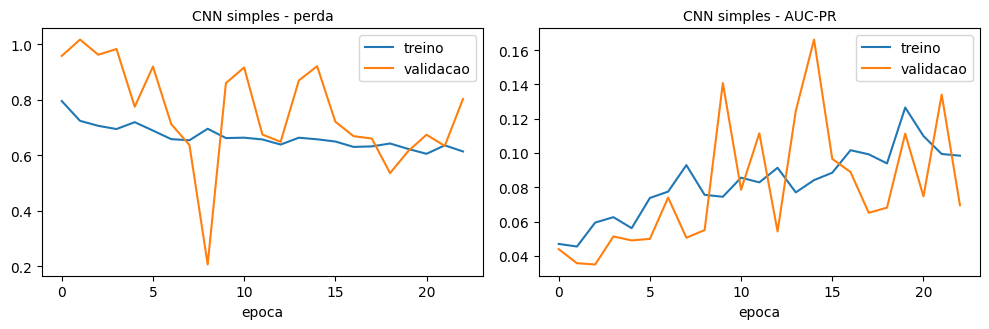

In [23]:
def construir_cnn_simples():
    entrada = keras.Input((TAMANHO, TAMANHO, 1), name="radiografia")
    x = camada_aumento()(entrada)
    x = layers.Rescaling(1.0 / 255, name="normalizacao")(x)
    for filtros in [16, 32, 64, 128, 128]:
        x = layers.Conv2D(filtros, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    saida = layers.Dense(1, activation="sigmoid", name="cardiomegalia")(x)
    return keras.Model(entrada, saida, name="cnn_simples")

cnn = construir_cnn_simples()
print("Parametros da CNN simples:", cnn.count_params())
hist_cnn = treinar(cnn, EPOCAS_CNN, lr=1e-3, paciencia=PACIENCIA_CNN)
print("Epocas executadas:", len(hist_cnn["loss"]))
grafico_treino(hist_cnn, "CNN simples", SAIDA / "nb2_treino_cnn_simples.png")

== CNN simples (do zero) ==
Limiar escolhido na validacao: 0.79 (F1 na validacao: 0.286)
Teste: 446 imagens, 19 positivos
               precision    recall  f1-score   support

  sem achados      0.967     0.895     0.929       427
cardiomegalia      0.118     0.316     0.171        19

     accuracy                          0.870       446
    macro avg      0.542     0.605     0.550       446
 weighted avg      0.931     0.870     0.897       446

acuracia        0.870
precisao        0.118 IC95% [0.000 - 0.250]
recall          0.316 IC95% [0.000 - 0.522]
f1              0.171 IC95% [0.000 - 0.318]
especificidade  0.895
auc_roc         0.668 IC95% [0.510 - 0.772]
auc_pr          0.085 IC95% [0.027 - 0.204]
Repeticoes de bootstrap validas: 1000


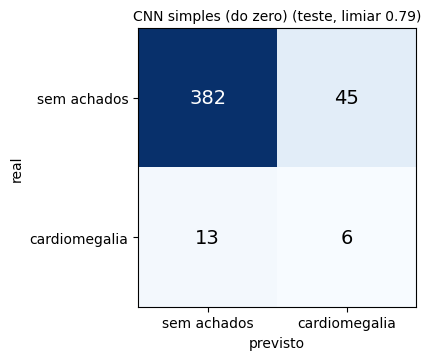

In [24]:
avaliar_modelo("cnn_simples", "CNN simples (do zero)", cnn)

## 7. Abordagem 2: Transfer Learning com ResNet50
A ResNet50 vem com pesos da ImageNet. A radiografia (1 canal) é replicada para 3 canais e recebe a subtração da média da ImageNet, como a ResNet50 do Keras espera. O treino tem duas fases:
1. **Cabeça:** a base fica congelada e só a camada final aprende (taxa 1e-3).
2. **Ajuste fino:** libera o último bloco convolucional (`conv5_`), mantendo as camadas BatchNormalization congeladas (taxa 1e-5).

A célula abaixo registra o tamanho da ResNet50 e da VGG16 (sem pesos, só para contar parâmetros). A VGG16 é a alternativa citada no enunciado.

In [25]:
vgg_ref = keras.applications.VGG16(include_top=False, weights=None, input_shape=(TAMANHO, TAMANHO, 3))
res_ref = keras.applications.ResNet50(include_top=False, weights=None, input_shape=(TAMANHO, TAMANHO, 3))
print("Parametros da base (sem a camada de saida): VGG16 = %d | ResNet50 = %d" % (vgg_ref.count_params(), res_ref.count_params()))
del vgg_ref, res_ref

def construir_resnet50():
    base = keras.applications.ResNet50(include_top=False, weights="imagenet", input_shape=(TAMANHO, TAMANHO, 3))
    base.trainable = False
    entrada = keras.Input((TAMANHO, TAMANHO, 1), name="radiografia")
    x = camada_aumento()(entrada)
    x = layers.Concatenate(name="replica_3_canais")([x, x, x])
    # Media da ImageNet (ordem BGR, a mesma nos 3 canais porque a imagem e cinza); variancia 1 = apenas subtrai a media
    x = layers.Normalization(mean=[103.939, 116.779, 123.68], variance=[1.0, 1.0, 1.0], axis=-1, name="media_imagenet")(x)
    x = base(x, training=False)   # training=False mantem as BatchNormalization da base em modo de inferencia
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    saida = layers.Dense(1, activation="sigmoid", name="cardiomegalia")(x)
    return keras.Model(entrada, saida, name="resnet50_transfer"), base

resnet, base_resnet = construir_resnet50()
print("Parametros totais: %d | treinaveis na fase 1: %d" % (resnet.count_params(), n_params(resnet.trainable_weights)))
hist_f1 = treinar(resnet, EPOCAS_FASE1, lr=1e-3, paciencia=PACIENCIA_RESNET)
print("Fase 1 - epocas executadas:", len(hist_f1["loss"]))

Parametros da base (sem a camada de saida): VGG16 = 14714688 | ResNet50 = 23587712
Parametros totais: 23589761 | treinaveis na fase 1: 2049
Epoch 1/15
72/72 - 12s - 163ms/step - auc: 0.5375 - auc_pr: 0.0474 - loss: 0.8204 - val_auc: 0.5639 - val_auc_pr: 0.0683 - val_loss: 0.8329 - learning_rate: 0.0010
Epoch 2/15
72/72 - 2s - 30ms/step - auc: 0.6546 - auc_pr: 0.0843 - loss: 0.7077 - val_auc: 0.6056 - val_auc_pr: 0.0690 - val_loss: 0.5816 - learning_rate: 0.0010
Epoch 3/15
72/72 - 2s - 31ms/step - auc: 0.6706 - auc_pr: 0.0997 - loss: 0.6898 - val_auc: 0.6034 - val_auc_pr: 0.0752 - val_loss: 1.2997 - learning_rate: 0.0010
Epoch 4/15
72/72 - 2s - 29ms/step - auc: 0.7495 - auc_pr: 0.1105 - loss: 0.5969 - val_auc: 0.6148 - val_auc_pr: 0.0725 - val_loss: 1.1394 - learning_rate: 0.0010
Epoch 5/15
72/72 - 2s - 29ms/step - auc: 0.7542 - auc_pr: 0.1291 - loss: 0.5985 - val_auc: 0.6083 - val_auc_pr: 0.0701 - val_loss: 0.8372 - learning_rate: 0.0010
Epoch 6/15
72/72 - 2s - 29ms/step - auc: 0.7643 

Parametros treinaveis na fase 2: 14955521
Epoch 1/15
72/72 - 14s - 190ms/step - auc: 0.7214 - auc_pr: 0.1233 - loss: 0.6348 - val_auc: 0.6444 - val_auc_pr: 0.0738 - val_loss: 0.6071 - learning_rate: 1.0000e-05
Epoch 2/15
72/72 - 3s - 39ms/step - auc: 0.8015 - auc_pr: 0.1846 - loss: 0.5385 - val_auc: 0.6658 - val_auc_pr: 0.0781 - val_loss: 0.6597 - learning_rate: 1.0000e-05
Epoch 3/15
72/72 - 3s - 37ms/step - auc: 0.8233 - auc_pr: 0.1641 - loss: 0.5170 - val_auc: 0.6745 - val_auc_pr: 0.0752 - val_loss: 0.3658 - learning_rate: 1.0000e-05
Epoch 4/15
72/72 - 3s - 37ms/step - auc: 0.8163 - auc_pr: 0.1964 - loss: 0.5296 - val_auc: 0.6712 - val_auc_pr: 0.0766 - val_loss: 0.9258 - learning_rate: 1.0000e-05
Epoch 5/15
72/72 - 3s - 40ms/step - auc: 0.8764 - auc_pr: 0.2790 - loss: 0.4374 - val_auc: 0.6930 - val_auc_pr: 0.0797 - val_loss: 0.4901 - learning_rate: 5.0000e-06
Epoch 6/15
72/72 - 3s - 37ms/step - auc: 0.9047 - auc_pr: 0.3833 - loss: 0.3857 - val_auc: 0.6839 - val_auc_pr: 0.0751 - val_l

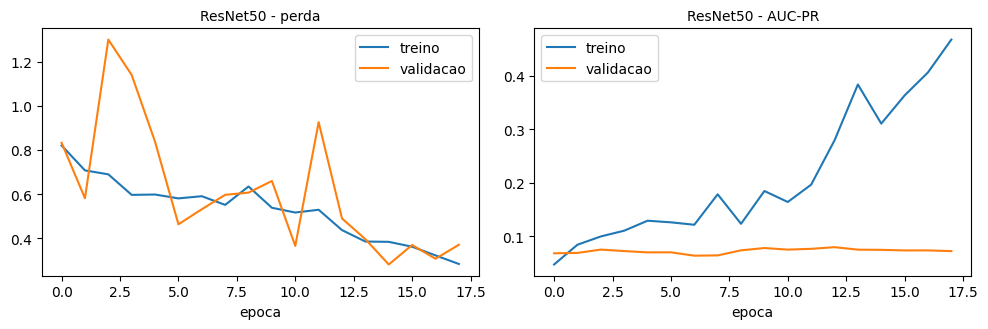

In [26]:
def liberar_ultimo_bloco(base, prefixo="conv5_"):
    """Libera so as camadas do ultimo bloco convolucional, exceto BatchNormalization."""
    base.trainable = True
    for camada in base.layers:
        camada.trainable = camada.name.startswith(prefixo) and not isinstance(camada, layers.BatchNormalization)

liberar_ultimo_bloco(base_resnet)
print("Parametros treinaveis na fase 2:", n_params(resnet.trainable_weights))
hist_f2 = treinar(resnet, EPOCAS_FASE2, lr=1e-5, paciencia=PACIENCIA_RESNET)
print("Fase 2 - epocas executadas:", len(hist_f2["loss"]))
hist_resnet = {k: hist_f1[k] + hist_f2[k] for k in hist_f1}
print("Os %d primeiros pontos dos graficos sao da fase 1; o restante, da fase 2." % len(hist_f1["loss"]))
grafico_treino(hist_resnet, "ResNet50", SAIDA / "nb2_treino_resnet50.png")

== ResNet50 (Transfer Learning) ==
Limiar escolhido na validacao: 0.35 (F1 na validacao: 0.172)
Teste: 446 imagens, 19 positivos
               precision    recall  f1-score   support

  sem achados      0.993     0.672     0.802       427
cardiomegalia      0.108     0.895     0.193        19

     accuracy                          0.682       446
    macro avg      0.551     0.783     0.497       446
 weighted avg      0.955     0.682     0.776       446

acuracia        0.682
precisao        0.108 IC95% [0.045 - 0.183]
recall          0.895 IC95% [0.687 - 1.000]
f1              0.193 IC95% [0.085 - 0.306]
especificidade  0.672
auc_roc         0.845 IC95% [0.748 - 0.908]
auc_pr          0.157 IC95% [0.059 - 0.345]
Repeticoes de bootstrap validas: 1000


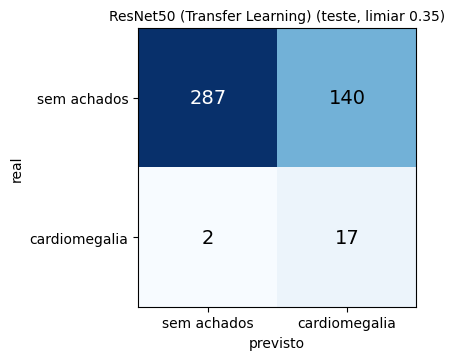

In [27]:
avaliar_modelo("resnet50", "ResNet50 (Transfer Learning)", resnet)

## 8. Comparação final no conjunto de teste
Os intervalos de confiança mostram o quanto o resultado pode variar com outra amostra de pacientes. Se os intervalos de dois modelos se sobrepõem, a diferença entre eles **não** está demonstrada por este teste.

,limiar,acuracia,precisao,recall,f1,auc_roc,auc_pr
modelo,,,,,,,
Referencia: sempre 'sem achados',-,0.957,0.000,0.000,0.000,0.500,0.043
CNN simples (do zero),0.79,0.870,0.118 [0.000 - 0.250],0.316 [0.000 - 0.522],0.171 [0.000 - 0.318],0.668 [0.510 - 0.772],0.085 [0.027 - 0.204]
ResNet50 (Transfer Learning),0.35,0.682,0.108 [0.045 - 0.183],0.895 [0.687 - 1.000],0.193 [0.085 - 0.306],0.845 [0.748 - 0.908],0.157 [0.059 - 0.345]


Teste: 446 imagens, 19 positivos. IC95% por bootstrap de pacientes. O AUC-PR da referencia e a prevalencia.


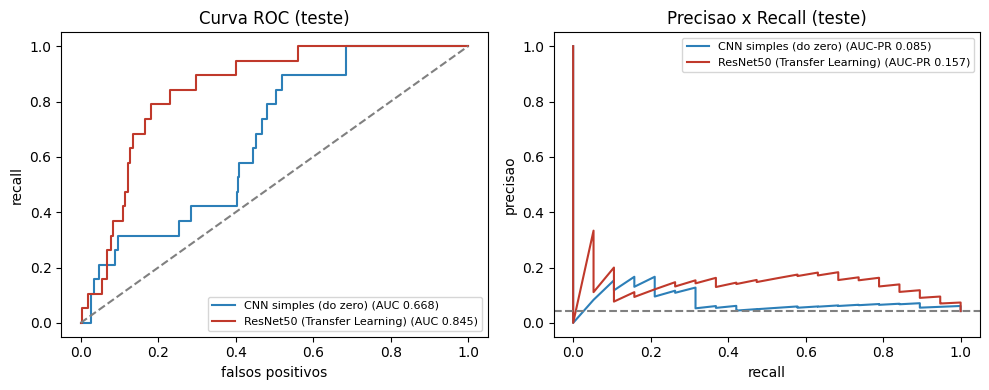

In [28]:
def faixa(chave, nome):
    r = RESULTADOS[chave]
    if nome in r["ic95"]:
        lo, hi = r["ic95"][nome]
        return "%.3f [%.3f - %.3f]" % (r["teste"][nome], lo, hi)
    return "%.3f" % r["teste"][nome]

linhas = [{"modelo": "Referencia: sempre 'sem achados'", "limiar": "-", "acuracia": "%.3f" % baseline["acuracia"], "precisao": "%.3f" % baseline["precisao"],
           "recall": "%.3f" % baseline["recall"], "f1": "%.3f" % baseline["f1"], "auc_roc": "0.500", "auc_pr": "%.3f" % (yte.mean())}]
for chave in ["cnn_simples", "resnet50"]:
    linhas.append({"modelo": RESULTADOS[chave]["rotulo"], "limiar": "%.2f" % RESULTADOS[chave]["limiar"],
                   **{nome: faixa(chave, nome) for nome in ["acuracia", "precisao", "recall", "f1", "auc_roc", "auc_pr"]}})
comparacao = pd.DataFrame(linhas).set_index("modelo")
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 20)
display(comparacao)
print("Teste: %d imagens, %d positivos. IC95%% por bootstrap de pacientes. O AUC-PR da referencia e a prevalencia." % (len(yte), int(yte.sum())))

fig, eixos = plt.subplots(1, 2, figsize=(10, 4))
for chave, cor in [("cnn_simples", "#2c7fb8"), ("resnet50", "#c0392b")]:
    fpr, tpr, _ = roc_curve(yte, PREVISOES[chave])
    prec, rec, _ = precision_recall_curve(yte, PREVISOES[chave])
    eixos[0].plot(fpr, tpr, color=cor, label="%s (AUC %.3f)" % (RESULTADOS[chave]["rotulo"], RESULTADOS[chave]["teste"]["auc_roc"]))
    eixos[1].plot(rec, prec, color=cor, label="%s (AUC-PR %.3f)" % (RESULTADOS[chave]["rotulo"], RESULTADOS[chave]["teste"]["auc_pr"]))
eixos[0].plot([0, 1], [0, 1], "--", color="gray"); eixos[0].set_title("Curva ROC (teste)"); eixos[0].set_xlabel("falsos positivos"); eixos[0].set_ylabel("recall")
eixos[1].axhline(yte.mean(), ls="--", color="gray"); eixos[1].set_title("Precisao x Recall (teste)"); eixos[1].set_xlabel("recall"); eixos[1].set_ylabel("precisao")
for ax in eixos:
    ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(SAIDA / "nb2_roc_pr_teste.png", dpi=130); plt.show()

## 9. Salvar modelos, métricas e arquivos para o repositório
Os modelos (`.keras`) ficam só no Drive, para o Notebook 3 (protótipo) e o Notebook 4 (fairness). Os arquivos pequenos vão para o repositório. O JSON reúne todos os números que o README e os relatórios vão citar.

In [29]:
cnn.save(SAIDA / "modelo_cnn_simples.keras")
resnet.save(SAIDA / "modelo_resnet50.keras")

metricas = {
    "semente": SEED,
    "teste": {"imagens": int(len(yte)), "positivos": int(yte.sum()), "pacientes": int(len(set(pac_teste)))},
    "peso_de_classe": {str(k): round(v, 4) for k, v in PESOS.items()},
    "hiperparametros": {
        "batch": BATCH, "cnn_epocas_max": EPOCAS_CNN, "cnn_paciencia": PACIENCIA_CNN, "cnn_lr": 1e-3,
        "resnet_fase1_epocas_max": EPOCAS_FASE1, "resnet_fase1_lr": 1e-3,
        "resnet_fase2_epocas_max": EPOCAS_FASE2, "resnet_fase2_lr": 1e-5, "resnet_paciencia": PACIENCIA_RESNET,
    },
    "epocas_executadas": {"cnn_simples": len(hist_cnn["loss"]), "resnet50_fase1": len(hist_f1["loss"]), "resnet50_fase2": len(hist_f2["loss"])},
    "parametros": {"cnn_simples": int(cnn.count_params()), "resnet50": int(resnet.count_params())},
    "referencia_sempre_negativo": baseline,
    "modelos": RESULTADOS,
    "versoes": {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__,
                "scikit_learn": sklearn.__version__, "tensorflow": tf.__version__, "keras": keras.__version__},
}
(SAIDA / "metricas_nb2.json").write_text(json.dumps(metricas, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(metricas, indent=2, ensure_ascii=False))

{
  "semente": 42,
  "teste": {
    "imagens": 446,
    "positivos": 19,
    "pacientes": 395
  },
  "peso_de_classe": {
    "0": 0.523,
    "1": 11.385
  },
  "hiperparametros": {
    "batch": 32,
    "cnn_epocas_max": 40,
    "cnn_paciencia": 8,
    "cnn_lr": 0.001,
    "resnet_fase1_epocas_max": 15,
    "resnet_fase1_lr": 0.001,
    "resnet_fase2_epocas_max": 15,
    "resnet_fase2_lr": 1e-05,
    "resnet_paciencia": 5
  },
  "epocas_executadas": {
    "cnn_simples": 23,
    "resnet50_fase1": 8,
    "resnet50_fase2": 10
  },
  "parametros": {
    "cnn_simples": 245969,
    "resnet50": 23589761
  },
  "referencia_sempre_negativo": {
    "acuracia": 0.9573991031390134,
    "precisao": 0.0,
    "recall": 0.0,
    "f1": 0.0,
    "especificidade": 1.0,
    "auc_roc": 0.5,
    "auc_pr": 0.042600896860986545,
    "tn": 427,
    "fp": 0,
    "fn": 19,
    "tp": 0
  },
  "modelos": {
    "cnn_simples": {
      "rotulo": "CNN simples (do zero)",
      "limiar": 0.79,
      "f1_validacao_no_lim

In [31]:
# Reune os arquivos pequenos e baixa em um unico zip (Colab). Localmente, apenas informa a pasta.
pacote = SAIDA / "para_repositorio_nb2"
pacote.mkdir(exist_ok=True)
arquivos = ["metricas_nb2.json", "nb2_treino_cnn_simples.png", "nb2_treino_resnet50.png", "nb2_matriz_confusao_cnn_simples.png",
            "nb2_matriz_confusao_resnet50.png", "nb2_roc_pr_teste.png", "pred_teste_cnn_simples.csv", "pred_teste_resnet50.csv",
            "pred_val_cnn_simples.csv", "pred_val_resnet50.csv"]
for nome in arquivos:
    shutil.copy(SAIDA / nome, pacote / nome)
if COLAB:
    from google.colab import files
    zip_path = shutil.make_archive("/content/pulso_f4_nb2_saidas", "zip", pacote)
    files.download(zip_path)
else:
    print("Arquivos para o repositorio em:", pacote)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Limitações deste experimento
- O teste tem poucos positivos. Métricas de precisão, recall e F1 têm intervalos largos e devem ser lidas como estimativas, não como garantia de desempenho.
- O limiar foi escolhido na validação, que também tem poucos positivos. Outro limiar pode ser melhor com mais dados.
- Os rótulos vêm dos laudos que acompanham as imagens, não de validação clínica independente.
- Imagens com outras doenças foram excluídas no Notebook 1. O modelo não foi testado contra o caso de distinguir cardiomegalia de outros achados.
- Treino em GPU pode variar levemente entre execuções, mesmo com semente fixa.
- Um único conjunto de partições foi usado. Não há validação cruzada, então a variação causada por outra divisão dos pacientes não foi medida.

O próximo passo é o Notebook 3, com o protótipo que recebe uma radiografia e mostra a classificação, e o Notebook 4, com a análise de fairness por sexo.